In [1]:
import pandas as pd
import numpy as np
import pickle


from additives_microbiota.plotting import process_string, process_string_pretty_vars
from additives_microbiota.mb_utils import (
    taxonomy_dict,
    prevalence,
    dict_ASV_names,
    taxonID_shortName,
    compute_log_ratios_using_significant_features,
    birdman_plot_single_var,
)

In [2]:
run_suffix = "adjustedBatch"  # "unadjusted"  or "adjustedMany"

slurm_outputs_dir = f"./slurm_outputs/{run_suffix}"
topn_plots_dir = f"./topn_plots/{run_suffix}"

### Loading Metadata and Counts Data

In [3]:
meta = pd.read_csv("../../data/metadata_files/meta_zscores.csv", index_col=0)

In [4]:
path_counts_data = "~/WORK/qiime2_2024/qiime_processed_files/table_rarefied.tsv"
counts_data = pd.read_csv(path_counts_data, sep="\t", index_col=0, skiprows=1).T
counts_data.head()

### Example execution

In [5]:
var = "thickeners_stabilizers_emulsifiers_gelling_agents"
beta_var = pd.read_csv(
    f"{slurm_outputs_dir}/{var}/results/beta_var.tsv", sep="\t", index_col="Feature"
)
beta_var["Taxon"] = beta_var.index.map(taxonomy_dict)

beta_var.head()

,Intercept_mean,batch[T.batch_0682]_mean,batch[T.batch_1205]_mean,batch[T.batch_1599]_mean,batch[T.batch_2013]_mean,batch[T.batch_2718]_mean,thickeners_stabilizers_emulsifiers_gelling_agents_mean,Intercept_std,batch[T.batch_0682]_std,batch[T.batch_1205]_std,...,batch[T.batch_2718]_std,thickeners_stabilizers_emulsifiers_gelling_agents_std,Intercept_hdi,batch[T.batch_0682]_hdi,batch[T.batch_1205]_hdi,batch[T.batch_1599]_hdi,batch[T.batch_2013]_hdi,batch[T.batch_2718]_hdi,thickeners_stabilizers_emulsifiers_gelling_agents_hdi,Taxon
Feature,,,,,,,,,,,,,,,,,,,,,
7e9ed2c841e64976eace4b578ff56a26,-5.001311,-0.287207,0.298438,-0.098280,0.234508,0.194364,-0.005486,0.343362,0.420236,0.424437,...,0.426040,0.102483,"(-5.60991, -4.34991)","(-1.11737, 0.487559)","(-0.451972, 1.118)","(-0.921907, 0.668372)","(-0.576499, 0.967443)","(-0.6174, 0.981031)","(-0.202319, 0.176561)",d__Bacteria; p__Bacillota_A_368345; c__Clostri...
a6099802840e60febef8e896967b7747,-7.196816,0.203876,0.287930,0.386685,0.300271,0.495863,-0.040532,0.110487,0.134559,0.137721,...,0.137059,0.037331,"(-7.40221, -6.98982)","(-0.0434424, 0.461578)","(0.0204311, 0.545405)","(0.141169, 0.625781)","(0.0335076, 0.542452)","(0.236315, 0.741926)","(-0.107628, 0.0287966)",d__Bacteria; p__Bacillota_A_368345; c__Clostri...
904ad13c7b8512200836d5cd9fb09e1b,-9.101783,0.650219,0.350331,0.093326,0.418065,-0.015909,-0.122406,0.282677,0.328627,0.335291,...,0.340541,0.093021,"(-9.63659, -8.58226)","(0.0658146, 1.31444)","(-0.246349, 1.00679)","(-0.608326, 0.675062)","(-0.223247, 1.03159)","(-0.655713, 0.588297)","(-0.297947, 0.0515586)",d__Bacteria; p__Bacteroidota; c__Bacteroidia; ...
1aab913302590e21a7be28b1494a3320,-9.152932,0.064186,0.052070,-0.088048,0.056936,0.174986,-0.001440,0.159267,0.186884,0.189187,...,0.197320,0.053460,"(-9.43313, -8.84276)","(-0.304936, 0.384474)","(-0.29652, 0.423703)","(-0.472406, 0.242627)","(-0.290293, 0.424311)","(-0.170889, 0.549983)","(-0.104606, 0.0951019)",d__Bacteria; p__Bacillota_A_368345; c__Clostri...
e644522cf6d7222c9da7f9ecf614cd89,-8.642078,-0.271506,-0.049936,-0.710053,-0.394686,0.463709,0.019787,0.270050,0.318861,0.324659,...,0.321824,0.087073,"(-9.14483, -8.13562)","(-0.899885, 0.294883)","(-0.700005, 0.51873)","(-1.36929, -0.154899)","(-0.952618, 0.259039)","(-0.141563, 1.05505)","(-0.153435, 0.179185)",d__Bacteria; p__Bacteroidota; c__Bacteroidia; ...


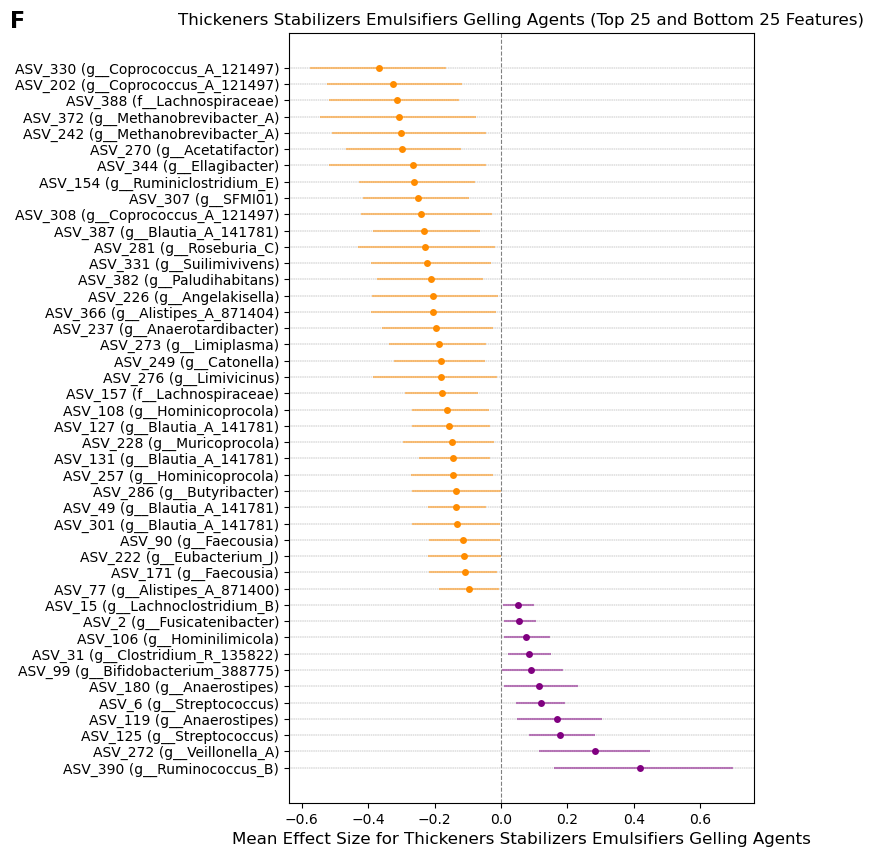

In [6]:
birdman_plot_single_var(
    beta_var,
    var,
    action="plot",
    n=25,
    plot_path=None,  # "../../figures/diff_abun_figs/beta_var_HEI.png",
    annotate_plot_args={"text": "F", "textpos": (-0.6, 1.03)},
)

## Running for All variables

In [7]:
additive_vars = [
    "thickeners_stabilizers_emulsifiers_gelling_agents",
    "sweeteners_glazing_agents",
    "preservatives_antioxidants",
    "ph_regulators_anti_caking_leavening_agents",
    # "other_additives",
    "flavor_enhancers",
    "colorants",
    "total_additive_intake",
]

mixtures = [
    "Mixture1",
    "Mixture2",
    "Mixture3",
]

folders = (
    additive_vars
    + mixtures
    + [
        "HEI",
        "HEI_minus_colorants",
        "HEI_minus_preservatives_antioxidants",
        "HEI_minus_thickeners_stabilizers_emulsifiers_gelling_agents",
        "HEI_minus_ph_regulators_anti_caking_leavening_agents",
        "HEI_minus_flavor_enhancers",
        "HEI_minus_sweeteners_glazing_agents",
        # "HEI_minus_other_additives",
        "HEI_minus_total_additive_intake",
        "HEI_minus_fast_food",
        "fruits_fg_eaten",
        "fruits_minus_colorants",
        "fruits_minus_preservatives_antioxidants",
        "fruits_minus_thickeners_stabilizers_emulsifiers_gelling_agents",
        "fruits_minus_ph_regulators_anti_caking_leavening_agents",
        "fruits_minus_flavor_enhancers",
        "fruits_minus_sweeteners_glazing_agents",
        # "fruits_minus_other_additives",
        "fruits_minus_total_additive_intake",
        "fruits_minus_fast_food",
        "vegetables_fg_eaten",
        "vegetables_minus_colorants",
        "vegetables_minus_preservatives_antioxidants",
        "vegetables_minus_thickeners_stabilizers_emulsifiers_gelling_agents",
        "vegetables_minus_ph_regulators_anti_caking_leavening_agents",
        "vegetables_minus_flavor_enhancers",
        "vegetables_minus_sweeteners_glazing_agents",
        # "vegetables_minus_other_additives",
        "vegetables_minus_total_additive_intake",
        "vegetables_minus_fast_food",
        "fast_food_fg_eaten",
    ]
    + [
        "HEI_minus_Mixture1",
        "HEI_minus_Mixture2",
        "HEI_minus_Mixture3",
        "fruits_minus_Mixture1",
        "fruits_minus_Mixture2",
        "fruits_minus_Mixture3",
        "vegetables_minus_Mixture1",
        "vegetables_minus_Mixture2",
        "vegetables_minus_Mixture3",
    ]
)

In [8]:
# folders = fetch_folders(slurm_outputs_dir)


diffAbun_res = []
respectively_asvs = {}
corr_dict_all = {}
sq_corrs = []
numerator_asvs_dict = {}
denominator_asvs_dict = {}

for e, var in enumerate(sorted(folders)):
    beta_var = pd.read_csv(
        f"{slurm_outputs_dir}/{var}/results/beta_var.tsv", sep="\t", index_col="Feature"
    )
    significant_feats = birdman_plot_single_var(beta_var, var, action="get_top_n", n=50)
    significant_feats["Taxon"] = significant_feats["Feature"].map(taxonomy_dict)

    if significant_feats.shape[0] > 0:
        birdman_plot_single_var(
            beta_var,
            var,
            action="plot",
            n=25,
            plot_path=f"{topn_plots_dir}/{var}.png",
        )

        log_ratios, corr, corr_dict, num_numerator_asvs, num_denominator_asvs = (
            compute_log_ratios_using_significant_features(
                counts_data, var, significant_feats, meta, folders
            )
        )
        corr_dict_all[f"LR_({var})"] = corr_dict
        diffAbun_res.append(
            [
                var,
                len(significant_feats),
                corr,
                len(num_numerator_asvs),
                len(num_denominator_asvs),
            ]
        )
        numerator_asvs_dict[var] = num_numerator_asvs
        denominator_asvs_dict[var] = num_denominator_asvs

        respectively_asvs[var] = significant_feats["Feature"].values

        if e == 0:
            lr = log_ratios
        else:
            lr = lr.merge(log_ratios[["sample-id", "Log Ratio"]], on="sample-id")
        lr.rename(columns={"Log Ratio": "LR_" + var}, inplace=True)

    significant_feats.to_csv(
        f"{slurm_outputs_dir}/{var}/results/differential_taxa.tsv", sep="\t"
    )


with open(f"./results_files/numerator_asvs_dict_{run_suffix}.pkl", "wb") as f:
    pickle.dump(numerator_asvs_dict, f)

with open(f"./results_files/denominator_asvs_dict_{run_suffix}.pkl", "wb") as f:
    pickle.dump(denominator_asvs_dict, f)

Common Samples: (974,) 	HEI 	 Pearson Correlation HEI: 0.43 	 P-value: 3.77e-45
Common Samples: (974,) 	HEI_minus_Mixture1 	 Pearson Correlation HEI_minus_Mixture1: 0.37 	 P-value: 2.55e-33
Common Samples: (974,) 	HEI_minus_Mixture2 	 Pearson Correlation HEI_minus_Mixture2: 0.38 	 P-value: 4.31e-35
Common Samples: (974,) 	HEI_minus_Mixture3 	 Pearson Correlation HEI_minus_Mixture3: 0.37 	 P-value: 9.65e-33
Common Samples: (973,) 	HEI_minus_colorants 	 Pearson Correlation HEI_minus_colorants: 0.37 	 P-value: 1.03e-32
Common Samples: (974,) 	HEI_minus_fast_food 	 Pearson Correlation HEI_minus_fast_food: 0.45 	 P-value: 6.50e-50
Common Samples: (975,) 	HEI_minus_flavor_enhancers 	 Pearson Correlation HEI_minus_flavor_enhancers: 0.38 	 P-value: 2.90e-35
Common Samples: (974,) 	HEI_minus_ph_regulators_anti_caking_leavening_agents 	 Pearson Correlation HEI_minus_ph_regulators_anti_caking_leavening_agents: 0.39 	 P-value: 1.39e-37
Common Samples: (974,) 	HEI_minus_preservatives_antioxidants 	

In [9]:
lr.to_csv(f"../../data/metadata_files/meta_log_ratios_{run_suffix}.csv")
print(lr.shape)

(957, 312)


In [10]:
diffAbun_res_df = pd.DataFrame(
    diffAbun_res,
    columns=[
        "variable",
        "num_feats",
        "corr",
        "num_numerator_asvs",
        "num_denominator_asvs",
    ],
)

diffAbun_res_df.to_csv(
    f"./results_files/differential_abundance_mirrorplot_stats_{run_suffix}.csv"
)